# Rust vs Python — end-to-end inference speed (PBMC 10k)

This notebook times the **complete inference pipeline** — from raw `.h5ad` file to
optimised biophysical parameters — and compares three configurations:

| Configuration | Data loading | Optimizer |
|---|---|---|
| **Python (serial)** | `extract_data` + `searchdata_from_adata` (Python) | serial scipy L-BFGS-B |
| **Python (+ threads)** | same Python path | scipy + `ThreadPoolExecutor` (all cores) |
| **Rust (full)** | `searchdata_from_h5ad` (GIL-free Rust) | Rust `optimize_genes_2d` (rayon) |

The **Python** configurations run with the `monod_core` extension disabled: all Python, scipy only.  
The **Rust** configuration enables every Rust fast-path simultaneously.

**Dataset**: `processed_pbmc_10k_raw.h5ad` — 10 997 cells × 36 601 genes  
**Model**: Bursty + Poisson (3 log₁₀ physical parameters per gene)  
**Grid**: 3×4 = 12 sampling-rate points (biologically realistic; recovers capture efficiency)  
**Gene counts**: 25 – 1 000 (all real runs)  

## Setup

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import gc, sys, os, time, warnings
os.makedirs('figures', exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import anndata as ad
import scipy.sparse as _ssp
warnings.filterwarnings('ignore')


import monod.cme_toolbox as cme_toolbox
import monod.extract_data as _ed_bare
from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.extract_data import extract_data
from monod.inference import InferenceParameters, searchdata_from_adata
import monod_core as _mc

n_cpu = os.cpu_count() or 4
print(f'Rust extension: {_HAS_RUST}')
print(f'Logical CPUs:   {n_cpu}')

Rust extension: True
Logical CPUs:   24


## Configuration

In [3]:
H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
MODEL     = CMEModel('Bursty', 'Poisson')
N_ITER      = 50   # L-BFGS-B iterations for main-serial (scipy)
N_ITER_RUST = 200  # Rust optimizer can afford 4× more iter at same wall time
GRIDSIZE  = [3, 4] # 12-point sampling-rate grid (biologically realistic)

# ── Build expressed-gene list once using sparse arithmetic (no dense copy) ───
_adata_ref = ad.read_h5ad(H5AD_PATH)
_s_sp = _adata_ref.layers['spliced']
if _ssp.issparse(_s_sp):
    _mask = np.asarray(_s_sp.getnnz(axis=0)) >= 10
else:
    _mask = (_s_sp > 0).sum(0) >= 10
EXPR_GENES = list(_adata_ref.var_names[_mask])
del _adata_ref, _s_sp, _mask
gc.collect()
print(f'Expressed genes (>=10 cells): {len(EXPR_GENES)}')

# Gene counts to sweep
# n=500 included as a real scaling checkpoint before projecting to 1000.
# At [3,4], main-serial at n=500 takes ~4-5 min; within the 30-min timeout.
N_ITER_CONC    = N_ITER_RUST  # iterations for all concordance runs (both optimizers)
N_RESTARTS_OPT = 3            # restarts for optimizer concordance (timing uses 1)

N_SWEEP = [25, 50, 100, 200, 500, 1000]

# Colour palette (matches other demo notebooks)
C_SERIAL  = '#d73027'   # dark red  — main serial
C_THREADS = '#fc8d59'   # orange    — main + threads
C_RUST    = 'steelblue' # blue      — rusty full

Expressed genes (>=10 cells): 16244


## Timing functions

Each function returns `(t_load_ms, t_infer_ms)`.  
All large allocations are local to the function so they are freed on return.

In [4]:
def _make_ip(n_gene_cores, use_rust_lbfgsb=False, n_iter=None):
    if n_iter is None:
        n_iter = N_ITER_RUST if use_rust_lbfgsb else N_ITER
    gp = {
        'max_iterations': n_iter,
        'init_pattern': 'moments',
        'num_restarts': 1,  # 1 restart: MoM x0 (deterministic)
        'num_gene_cores': n_gene_cores,
        'use_rust_lbfgsb': use_rust_lbfgsb,
    }
    return InferenceParameters(
        'bench', MODEL, use_lengths=False,
        gradient_params=gp, gridsize=GRIDSIZE, save=False,
    )


def time_main(genes_n, num_gene_cores=1):
    # Main-branch equivalent: Python extract_data + scipy L-BFGS-B.
    # Returns (t_load_ms, t_infer_ms, phys_optimum).
    cme_toolbox._HAS_RUST = False
    _ed_bare._HAS_RUST    = False

    t0 = time.perf_counter()
    adata_ex = extract_data(
        H5AD_PATH, MODEL,
        dataset_name='bench',
        modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
        n_genes=len(genes_n), genes_to_fit=genes_n,
        hist_type='unique', viz=False,
    )
    sd = searchdata_from_adata(adata_ex)
    t_load = (time.perf_counter() - t0) * 1e3
    del adata_ex; gc.collect()

    ip = _make_ip(num_gene_cores, use_rust_lbfgsb=False)
    t0 = time.perf_counter()
    result = ip.fit_all_grid_points(sd, num_cores=1, save=False)
    t_infer = (time.perf_counter() - t0) * 1e3
    result.find_sampling_optimum()
    params = result.phys_optimum.copy()
    del sd, result; gc.collect()

    cme_toolbox._HAS_RUST = _HAS_RUST
    _ed_bare._HAS_RUST    = _HAS_RUST
    return t_load, t_infer, params


def time_rusty_full(genes_n):
    # Rusty full: searchdata_from_h5ad + Rust L-BFGS-B (rayon).
    # Returns (t_load_ms, t_infer_ms, phys_optimum).
    t0 = time.perf_counter()
    sd = _mc.searchdata_from_h5ad(
        H5AD_PATH, ['unspliced', 'spliced'], gene_names=genes_n
    )
    t_load = (time.perf_counter() - t0) * 1e3

    ip = _make_ip(n_gene_cores=-1, use_rust_lbfgsb=True)
    t0 = time.perf_counter()
    result = ip.fit_all_grid_points(sd, num_cores=1, save=False)
    t_infer = (time.perf_counter() - t0) * 1e3
    result.find_sampling_optimum()
    params = result.phys_optimum.copy()
    del sd, result; gc.collect()

    return t_load, t_infer, params


## Gene-count sweep

Timing three configurations at 25 – 200 genes.

In [5]:
results = {}  # (config, n) -> (t_load_ms, t_infer_ms, phys_optimum)

configs = [
    ('main_serial',   lambda g: time_main(g, num_gene_cores=1)),
    ('main_threads',  lambda g: time_main(g, num_gene_cores=-1)),
    ('rusty_full',    time_rusty_full),
]

hdr = f'{"n":>5}  {"Config":<22}  {"Load (ms)":>10}  {"Infer (ms)":>11}  {"Total (ms)":>11}'
print(hdr)
print('-' * len(hdr))

for n in N_SWEEP:
    genes_n = EXPR_GENES[:n]
    for cfg_name, fn in configs:
        t_load, t_infer, params = fn(genes_n)
        results[(cfg_name, n)] = (t_load, t_infer, params)
        print(f'{n:5d}  {cfg_name:<22}  {t_load:10.0f}  {t_infer:11.0f}  {t_load+t_infer:11.0f}')
    t_ms = results[('main_serial',  n)][0] + results[('main_serial',  n)][1]
    t_mt = results[('main_threads', n)][0] + results[('main_threads', n)][1]
    t_ru = results[('rusty_full',   n)][0] + results[('rusty_full',   n)][1]
    print(f'       speedup vs main serial: threads={t_ms/t_mt:.1f}×  rusty={t_ms/t_ru:.1f}×')
    print()


    n  Config                   Load (ms)   Infer (ms)   Total (ms)
-------------------------------------------------------------------


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:12,  1.15s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:10,  1.04s/it]

Grid scan:  25%|██▌       | 3/12 [00:03<00:09,  1.01s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:08<00:01,  1.41it/s]

Grid scan:  92%|█████████▏| 11/12 [00:08<00:00,  1.34it/s]

Grid scan: 100%|██████████| 12/12 [00:09<00:00,  1.45it/s]

Grid scan: 100%|██████████| 12/12 [00:09<00:00,  1.26it/s]

 1000  rusty_full                    3124         9516        12641
       speedup vs main serial: threads=0.6×  rusty=70.7×



## Plot

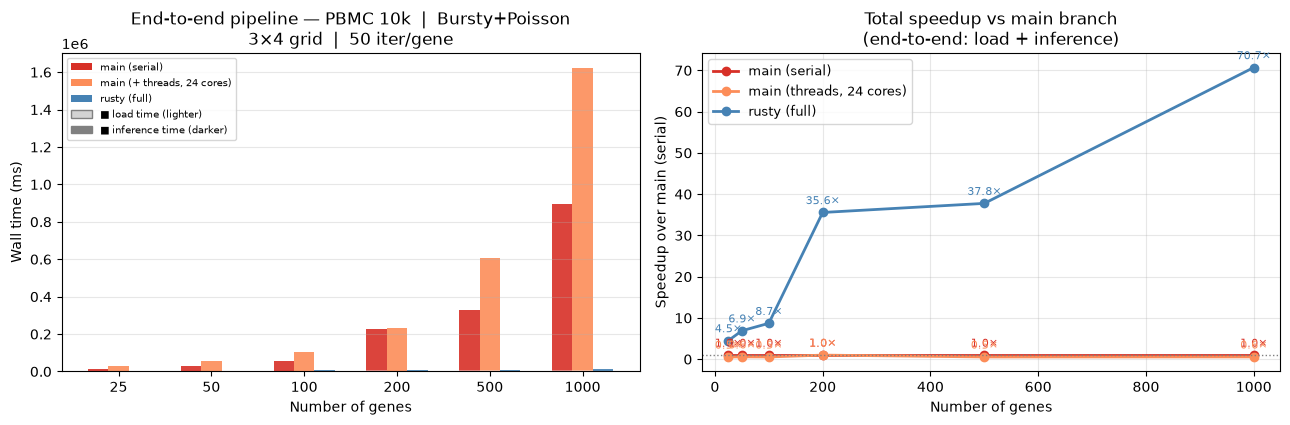

Saved figures/rusty_vs_main_speed.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ── Left: stacked bar at each gene count ─────────────────────────────────────────────
ax = axes[0]
x = np.arange(len(N_SWEEP))
width = 0.22

cfg_styles = [
    ('main_serial',  C_SERIAL,  'main (serial)\nextract_data + scipy'),
    ('main_threads', C_THREADS, f'main (threads, {n_cpu} cores)\nextract_data + scipy ThreadPool'),
    ('rusty_full',   C_RUST,    'rusty (full)\nsearchdata_from_h5ad + Rust L-BFGS-B'),
]

offsets = [-width, 0, width]
for (cfg, color, label), off in zip(cfg_styles, offsets):
    loads  = [results[(cfg, n)][0] for n in N_SWEEP]
    infers = [results[(cfg, n)][1] for n in N_SWEEP]
    ax.bar(x + off, loads,  width, color=color, alpha=0.55)
    ax.bar(x + off, infers, width, color=color, alpha=0.90, bottom=loads)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=C_SERIAL,  label='main (serial)'),
    Patch(facecolor=C_THREADS, label=f'main (+ threads, {n_cpu} cores)'),
    Patch(facecolor=C_RUST,    label='rusty (full)'),
    Patch(facecolor='lightgrey', edgecolor='grey', label='■ load time (lighter)'),
    Patch(facecolor='grey',      edgecolor='grey', label='■ inference time (darker)'),
]
ax.legend(handles=legend_handles, fontsize=7.5, loc='upper left')
ax.set_xticks(x)
ax.set_xticklabels(N_SWEEP)
ax.set_xlabel('Number of genes')
ax.set_ylabel('Wall time (ms)')
ax.set_title(f'End-to-end pipeline — PBMC 10k  |  Bursty+Poisson\n'
             f'3×4 grid  |  {N_ITER} iter/gene')
ax.grid(True, alpha=0.3, axis='y')

# ── Right: total speedup vs main serial ─────────────────────────────────────────
ax2 = axes[1]
for (cfg, color, label) in cfg_styles:
    totals  = [results[(cfg, n)][0] + results[(cfg, n)][1] for n in N_SWEEP]
    base    = [results[('main_serial', n)][0] + results[('main_serial', n)][1] for n in N_SWEEP]
    speedup = [b / t for b, t in zip(base, totals)]
    lbl = label.split('\n')[0]
    ax2.plot(N_SWEEP, speedup, 'o-', color=color, label=lbl, linewidth=2, markersize=6)
    for n, sp in zip(N_SWEEP, speedup):
        ax2.annotate(f'{sp:.1f}×', (n, sp), textcoords='offset points',
                     xytext=(0, 6), ha='center', fontsize=8, color=color)

ax2.axhline(1, color='grey', linestyle=':', linewidth=1)
ax2.set_xlabel('Number of genes')
ax2.set_ylabel('Speedup over main (serial)')
ax2.set_title('Total speedup vs main branch\n(end-to-end: load + inference)')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/rusty_vs_main_speed.png', dpi=150)
plt.show()
print('Saved figures/rusty_vs_main_speed.png')


## Result concordance

To isolate whether the **data path** affects inferred biology, both routes use
the same optimizer (scipy L-BFGS-B, 200 iterations) at n=200 genes.  
The only difference is how `SearchData` is built:
`extract_data` + `searchdata_from_adata` (Python) vs `searchdata_from_h5ad` (Rust).

Concordance: n=200, 3x4 grid, num_restarts=1 (MoM init)
  [scipy] Python data...


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:03<00:43,  3.95s/it]

Grid scan:  17%|█▋        | 2/12 [00:07<00:37,  3.70s/it]

Grid scan:  25%|██▌       | 3/12 [00:10<00:32,  3.60s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:02<00:00,  2.73it/s]

Grid scan:  92%|█████████▏| 11/12 [00:03<00:00,  3.04it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.36it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.55it/s]

  All done.


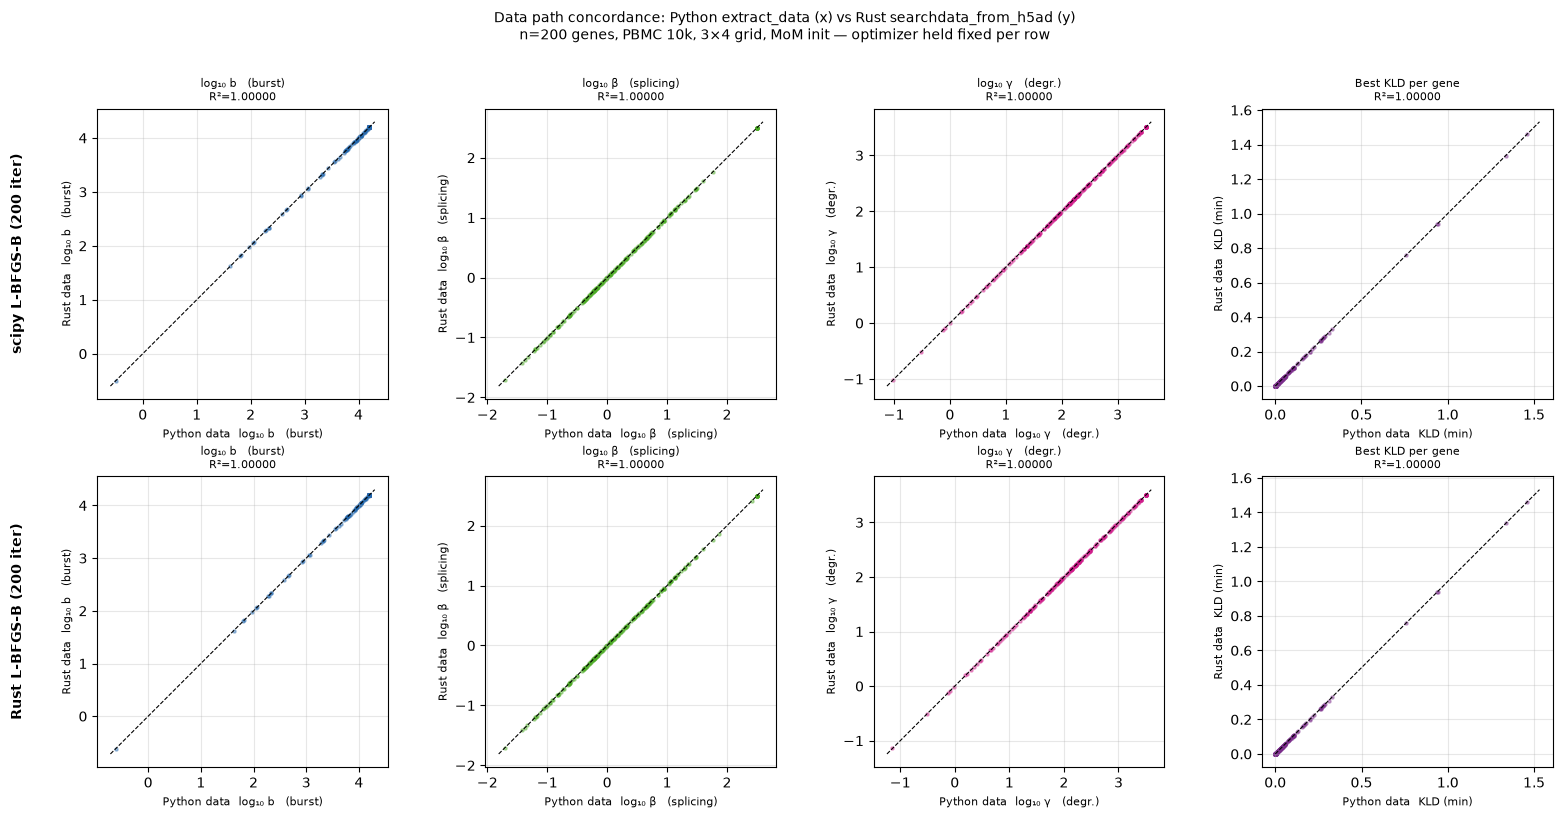

Saved figures/rusty_vs_main_concordance.png

scipy: Python vs Rust data:
  param max diff (log10): 0.0000  mean: 0.0000
  KLD  max diff:          0.000000  mean: 0.000000
  genes param diff > 0.1: 0

Rust opt: Python vs Rust data:
  param max diff (log10): 0.0000  mean: 0.0000
  KLD  max diff:          0.000000  mean: 0.000000
  genes param diff > 0.1: 0


In [7]:
# Data path concordance: does Python extract_data vs Rust searchdata_from_h5ad
# give the same inferred biology?  Each row holds the optimizer fixed and varies
# only the data pipeline.  num_restarts=1 keeps initialization deterministic
# (MoM x0 only), so results depend solely on histogram data quality.
N_CONC_GENES = 200
GENES_CONC   = EXPR_GENES[:N_CONC_GENES]

def _run_conc(genes_n, use_rust_data, use_rust_optimizer=False):
    """Returns (params [n_genes x 3], klds [n_genes]).
    klds = best KLD per gene across all grid points (min over grid)."""
    gp = {
        'max_iterations': N_ITER_CONC,
        'init_pattern': 'moments',
        'num_restarts': 1,          # deterministic: MoM x0 only
        'num_gene_cores': -1,
        'use_rust_lbfgsb': use_rust_optimizer,
    }
    ip = InferenceParameters('bench', MODEL, use_lengths=False,
                             gradient_params=gp, gridsize=GRIDSIZE, save=False)
    if use_rust_data:
        sd = _mc.searchdata_from_h5ad(H5AD_PATH, ['unspliced', 'spliced'],
                                      gene_names=genes_n)
    else:
        cme_toolbox._HAS_RUST = False
        _ed_bare._HAS_RUST    = False
        adata_ex = extract_data(
            H5AD_PATH, MODEL, dataset_name='bench',
            modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
            n_genes=len(genes_n), genes_to_fit=genes_n,
            hist_type='unique', viz=False,
        )
        sd = searchdata_from_adata(adata_ex)
        del adata_ex
        cme_toolbox._HAS_RUST = _HAS_RUST
        _ed_bare._HAS_RUST    = _HAS_RUST
    result = ip.fit_all_grid_points(sd, num_cores=1, save=False)
    result.find_sampling_optimum()
    params = result.phys_optimum.copy()
    klds   = result.klds.min(axis=0).copy()  # best KLD per gene across all grid points
    del sd, result; gc.collect()
    return params, klds

print(f'Concordance: n={N_CONC_GENES}, 3x4 grid, num_restarts=1 (MoM init)')
print('  [scipy] Python data...')
params_scipy_py,   klds_scipy_py   = _run_conc(GENES_CONC, use_rust_data=False, use_rust_optimizer=False)
print('  [scipy] Rust data...')
params_scipy_rust, klds_scipy_rust = _run_conc(GENES_CONC, use_rust_data=True,  use_rust_optimizer=False)
print(f'  [Rust L-BFGS-B, {N_ITER_RUST} iter] Python data...')
params_rust_py,    klds_rust_py    = _run_conc(GENES_CONC, use_rust_data=False, use_rust_optimizer=True)
print(f'  [Rust L-BFGS-B, {N_ITER_RUST} iter] Rust data...')
params_rust_rust,  klds_rust_rust  = _run_conc(GENES_CONC, use_rust_data=True,  use_rust_optimizer=True)
print('  All done.')

param_names  = ['log\u2081\u2080 b\u2003(burst)', 'log\u2081\u2080 \u03b2\u2003(splicing)', 'log\u2081\u2080 \u03b3\u2003(degr.)']
param_colors = ['#2166ac', '#4dac26', '#d01c8b']

def _scatter_row(axes, x_params, y_params, x_klds, y_klds):
    for pi, (pname, color) in enumerate(zip(param_names, param_colors)):
        ax = axes[pi]
        xv, yv = x_params[:, pi], y_params[:, pi]
        ax.scatter(xv, yv, s=5, alpha=0.4, color=color, rasterized=True)
        lo = min(xv.min(), yv.min()) - 0.1
        hi = max(xv.max(), yv.max()) + 0.1
        ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
        r2 = float(np.corrcoef(xv, yv)[0, 1] ** 2)
        ax.set_xlabel(f'Python data  {pname}', fontsize=8)
        ax.set_ylabel(f'Rust data  {pname}', fontsize=8)
        ax.set_title(f'{pname}\nR\u00b2={r2:.5f}', fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal', 'box')
    ax = axes[3]
    ax.scatter(x_klds, y_klds, s=5, alpha=0.4, color='#7b2d8b', rasterized=True)
    lo = min(x_klds.min(), y_klds.min()) * 0.95
    hi = max(x_klds.max(), y_klds.max()) * 1.05
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    r2_kld = float(np.corrcoef(x_klds, y_klds)[0, 1] ** 2)
    ax.set_xlabel('Python data  KLD (min)', fontsize=8)
    ax.set_ylabel('Rust data  KLD (min)', fontsize=8)
    ax.set_title(f'Best KLD per gene\nR\u00b2={r2_kld:.5f}', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', 'box')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
_scatter_row(axes[0], params_scipy_py, params_scipy_rust, klds_scipy_py, klds_scipy_rust)
_scatter_row(axes[1], params_rust_py,  params_rust_rust,  klds_rust_py,  klds_rust_rust)

for row, label in enumerate([
    f'scipy L-BFGS-B ({N_ITER_CONC} iter)',
    f'Rust L-BFGS-B ({N_ITER_RUST} iter)',
]):
    axes[row][0].annotate(label, xy=(-0.3, 0.5), xycoords='axes fraction',
                          fontsize=10, fontweight='bold', va='center', rotation=90)

plt.suptitle(
    f'Data path concordance: Python extract_data (x) vs Rust searchdata_from_h5ad (y)\n'
    f'n={N_CONC_GENES} genes, PBMC 10k, 3\u00d74 grid, MoM init — optimizer held fixed per row',
    fontsize=10, y=1.01,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_concordance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_concordance.png')

for label, xp, yp, xk, yk in [
    (f'scipy: Python vs Rust data', params_scipy_py, params_scipy_rust, klds_scipy_py, klds_scipy_rust),
    (f'Rust opt: Python vs Rust data', params_rust_py, params_rust_rust, klds_rust_py, klds_rust_rust),
]:
    pd = np.abs(xp - yp)
    kd = np.abs(xk - yk)
    print(f'\n{label}:')
    print(f'  param max diff (log10): {pd.max():.4f}  mean: {pd.mean():.4f}')
    print(f'  KLD  max diff:          {kd.max():.6f}  mean: {kd.mean():.6f}')
    print(f'  genes param diff > 0.1: {(pd.max(1) > 0.1).sum()}')


## Optimizer concordance

To isolate whether the **optimizer** affects inferred biology, both routes use
the same data (`searchdata_from_h5ad`) at n=50 genes and vary only the optimizer.
Results are evaluated at **every grid point** (not just the sampling optimum) to
get a full picture of the L-BFGS-B landscape.

`np.random.seed(OPT_CONC_SEED)` is called before each run so scipy and Rust draw
**identical random restarts** (restarts 1 and 2 beyond the MoM restart).  Without
this, apparent discordance would conflate optimizer quality with initialization luck.

Key questions:
1. Where scipy and Rust find different parameters, do they have different KLDs
   (genuine optimizer failure) or the same KLD (flat-landscape degeneracy)?
2. Does either optimizer systematically miss the global minimum?

What to expect: the two optimizers implement the same algorithm (L-BFGS-B with
a More'-Thuente line search) on the same objective, so they should reach the
same minima.  Remaining parameter differences then come from flat directions
of the likelihood, where many parameter values give the same KLD, and should
show up as "similar KLD" rather than as one optimizer winning.

Both optimizers start every gene at every grid point from the same moments
estimate. Earlier versions of this notebook reported large parameter differences
at a quarter of the (gene, grid point) pairs, concentrated at grid points 1 to 3
and with scipy usually the loser. That was not the optimizer: the serial grid scan
warm-started the scipy fits from the previous grid point's optimum, which is a
systematically wrong start once the capture rate changes, and the Rust path never
did. The warm start was removed in 0.3.2 and the comparison below is now a fair one.


Optimizer concordance: n=50 genes, 200 iter each


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:14,  1.31s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:12,  1.26s/it]

Grid scan:  25%|██▌       | 3/12 [00:03<00:10,  1.14s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:02<00:00,  3.90it/s]

Grid scan:  92%|█████████▏| 11/12 [00:03<00:00,  3.97it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  4.35it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.68it/s]

  Rust:   3.3s  (3.8x faster)


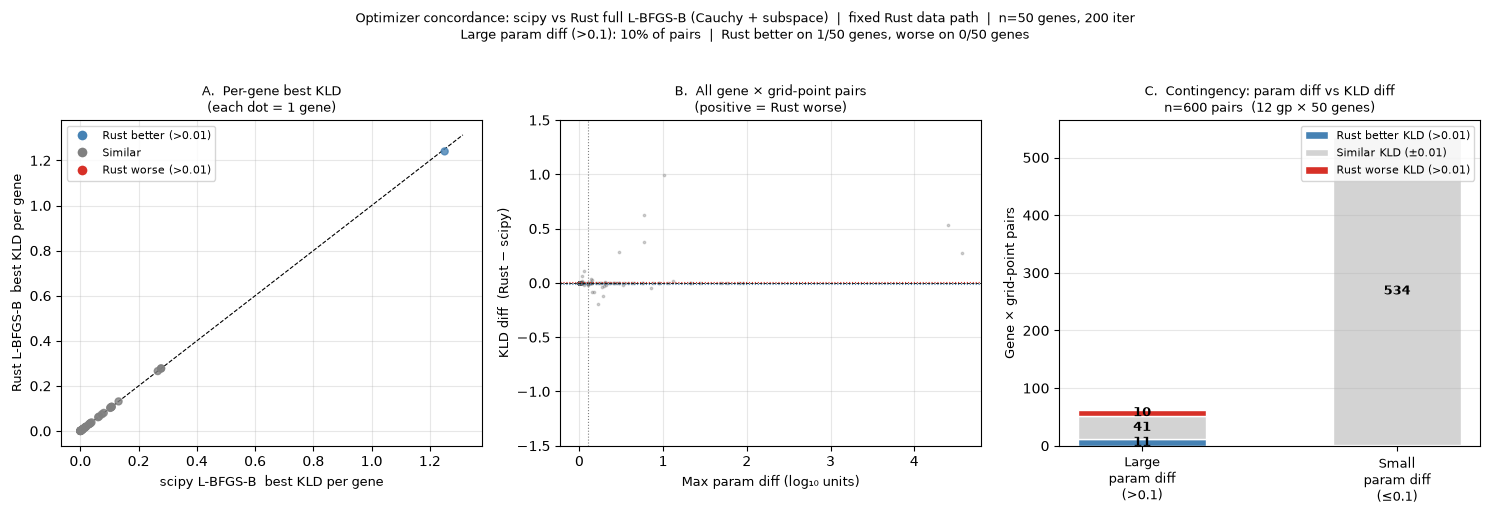

Saved figures/rusty_vs_main_opt_concordance.png

Optimizer concordance summary  (12 gp x 50 genes = 600 pairs):
  Large param diff (>0.1 log10):    62 / 600  (10%)
    of which Rust better KLD:   11  (2% of total)
    of which KLD similar:       41  ← flat landscape
    of which Rust worse KLD:    10
  Rust finds better per-gene min-KLD: 1/50 genes  (mean delta=-0.000)
  Rust finds worse  per-gene min-KLD: 0/50 genes


In [8]:
# Optimizer concordance: scipy vs Rust L-BFGS-B, fixed Rust data path.
# Evaluates all 12 grid points so we can classify disagreements.
N_OPT_GENES = 50
OPT_CONC_SEED = 42   # same random restarts for scipy and Rust
N_OPT_ITER  = N_ITER_CONC
GENES_OPT   = EXPR_GENES[:N_OPT_GENES]

sd_opt = _mc.searchdata_from_h5ad(H5AD_PATH, ['unspliced', 'spliced'],
                                   gene_names=GENES_OPT)

def _run_opt(use_rust, sd):
    """Returns (param_estimates [n_gp, n_genes, 3], klds [n_gp, n_genes])."""
    gp = {
        'max_iterations': N_OPT_ITER,
        'init_pattern': 'moments',
        'num_restarts': N_RESTARTS_OPT,
        'num_gene_cores': -1,
        'use_rust_lbfgsb': use_rust,
    }
    ip = InferenceParameters('bench', MODEL, use_lengths=False,
                             gradient_params=gp, gridsize=GRIDSIZE, save=False)
    import time
    t0 = time.perf_counter()
    result = ip.fit_all_grid_points(sd, num_cores=1, save=False)
    elapsed = time.perf_counter() - t0
    return result.param_estimates.copy(), result.klds.copy(), elapsed

print(f'Optimizer concordance: n={N_OPT_GENES} genes, {N_OPT_ITER} iter each')
np.random.seed(OPT_CONC_SEED)
p_sc, k_sc, t_sc = _run_opt(use_rust=False, sd=sd_opt)
print(f'  scipy:  {t_sc:.1f}s')
np.random.seed(OPT_CONC_SEED)
p_ru, k_ru, t_ru = _run_opt(use_rust=True,  sd=sd_opt)
print(f'  Rust:   {t_ru:.1f}s  ({t_sc/t_ru:.1f}x faster)')
del sd_opt; gc.collect()

# ── Classification ────────────────────────────────────────────────────────
n_gp_opt, n_gene_opt, _ = p_sc.shape
kld_diff  = k_ru - k_sc                          # positive = Rust worse
max_pdiff = np.abs(p_sc - p_ru).max(axis=2)      # (n_gp, n_genes)

PDIFF_T = 0.1    # log10
KLD_T   = 0.01   # KLD units

large_p   = max_pdiff > PDIFF_T
ru_worse  = kld_diff  >  KLD_T
ru_better = kld_diff  < -KLD_T
ru_same   = ~ru_worse & ~ru_better

# Per-gene min-KLD
k_sc_best = k_sc.min(axis=0)
k_ru_best = k_ru.min(axis=0)

# ── Figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ── Panel A: per-gene best KLD scatter ───────────────────────────────────
ax = axes[0]
delta = k_ru_best - k_sc_best
c_gene = np.where(delta < -KLD_T, C_RUST,
          np.where(delta >  KLD_T, C_SERIAL, 'grey'))
ax.scatter(k_sc_best, k_ru_best, c=c_gene, s=25, alpha=0.8, zorder=3)
lo = min(k_sc_best.min(), k_ru_best.min()) * 0.95
hi = max(k_sc_best.max(), k_ru_best.max()) * 1.05
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0], [0], marker='o', color='w', markerfacecolor=C_RUST,   ms=8, label=f'Rust better (>{KLD_T})'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey',   ms=8, label='Similar'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=C_SERIAL, ms=8, label=f'Rust worse (>{KLD_T})'),
], fontsize=8)
ax.set_xlabel('scipy L-BFGS-B  best KLD per gene', fontsize=9)
ax.set_ylabel('Rust L-BFGS-B  best KLD per gene', fontsize=9)
ax.set_title('A.  Per-gene best KLD\n(each dot = 1 gene)', fontsize=9)
ax.grid(True, alpha=0.3)

# ── Panel B: KLD diff vs param diff (all 600 gene-gp pairs) ──────────────
ax = axes[1]
ax.axhline(0, color='k', lw=0.6, ls='--')
ax.axhline( KLD_T, color=C_SERIAL, lw=0.8, ls=':')
ax.axhline(-KLD_T, color=C_RUST,   lw=0.8, ls=':')
ax.axvline(PDIFF_T, color='grey', lw=0.8, ls=':')
ax.scatter(max_pdiff.ravel(), kld_diff.ravel(), s=3, alpha=0.25, color='#555555', rasterized=True)
ax.set_xlabel(f'Max param diff (log₁₀ units)', fontsize=9)
ax.set_ylabel('KLD diff  (Rust − scipy)', fontsize=9)
ax.set_title('B.  All gene × grid-point pairs\n(positive = Rust worse)', fontsize=9)
ax.set_ylim(-1.5, 1.5)
ax.grid(True, alpha=0.3)

# ── Panel C: contingency stacked bar ─────────────────────────────────────
ax = axes[2]
groups = ['Large\nparam diff\n(>0.1)', 'Small\nparam diff\n(≤0.1)']
mask_large = large_p.ravel()
mask_small = ~mask_large

def _counts(mask):
    m = mask
    return [
        (m & ru_better.ravel()).sum(),
        (m & ru_same.ravel()).sum(),
        (m & ru_worse.ravel()).sum(),
    ]

cnts_large = _counts(mask_large)
cnts_small = _counts(mask_small)
colors_bar  = [C_RUST, 'lightgrey', C_SERIAL]
labels_bar  = [f'Rust better KLD (>{KLD_T})',
               f'Similar KLD (±{KLD_T})',
               f'Rust worse KLD (>{KLD_T})']

x_pos = np.array([0, 1])
bottoms = [0, 0]
for ci, (color, label) in enumerate(zip(colors_bar, labels_bar)):
    vals = [cnts_large[ci], cnts_small[ci]]
    ax.bar(x_pos, vals, bottom=bottoms, color=color, width=0.5, label=label, edgecolor='white')
    for xi, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 5:
            ax.text(xi, b + v/2, str(v), ha='center', va='center', fontsize=9, fontweight='bold')
    bottoms = [b + v for b, v in zip(bottoms, vals)]

ax.set_xticks(x_pos)
ax.set_xticklabels(groups, fontsize=9)
ax.set_ylabel('Gene × grid-point pairs', fontsize=9)
ax.set_title('C.  Contingency: param diff vs KLD diff\n'
             f'n={n_gp_opt * N_OPT_GENES} pairs  ({n_gp_opt} gp × {N_OPT_GENES} genes)', fontsize=9)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'Optimizer concordance: scipy vs Rust full L-BFGS-B (Cauchy + subspace)  |  '
    f'fixed Rust data path  |  n={N_OPT_GENES} genes, {N_OPT_ITER} iter\n'
    f'Large param diff (>{PDIFF_T}): {100*large_p.mean():.0f}% of pairs  |  '
    f'Rust better on {(delta < -KLD_T).sum()}/{N_OPT_GENES} genes, '
    f'worse on {(delta > KLD_T).sum()}/{N_OPT_GENES} genes',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_opt_concordance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_opt_concordance.png')

# ── Summary table ─────────────────────────────────────────────────────────
total = n_gp_opt * N_OPT_GENES
print(f'\nOptimizer concordance summary  ({n_gp_opt} gp x {N_OPT_GENES} genes = {total} pairs):')
print(f'  Large param diff (>{PDIFF_T} log10):  {large_p.sum():4d} / {total}  ({100*large_p.mean():.0f}%)')
print(f'    of which Rust better KLD: {(large_p & ru_better).sum():4d}  ({100*(large_p & ru_better).mean():.0f}% of total)')
print(f'    of which KLD similar:     {(large_p & ru_same  ).sum():4d}  ← flat landscape')
print(f'    of which Rust worse KLD:  {(large_p & ru_worse ).sum():4d}')
print(f'  Rust finds better per-gene min-KLD: {(delta < -KLD_T).sum()}/{N_OPT_GENES} genes  (mean delta={delta.mean():.3f})')
print(f'  Rust finds worse  per-gene min-KLD: {(delta >  KLD_T).sum()}/{N_OPT_GENES} genes')


### All-grid-point parameter scatter

Same scatter style at the level of every (gene, grid-point) pair — `n_gp × N_OPT_GENES` points total.  Reveals which part of parameter space drives the disagreements, and whether the two optimizers are consistently offset or only diverge on specific genes.

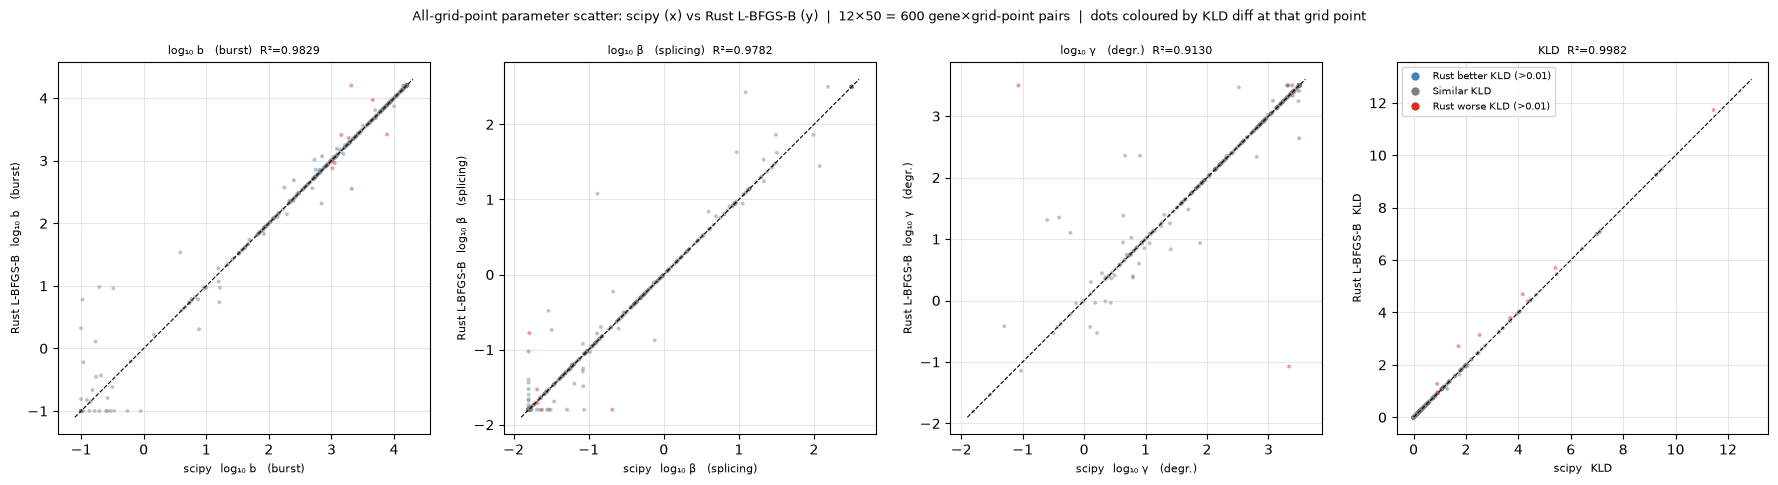

Saved figures/rusty_vs_main_allgp_scatter.png


In [9]:
# ── All-grid-point parameter scatter: scipy vs Rust L-BFGS-B ─────────────────
# Each dot = one (gene, grid-point) pair — n_gp_opt × N_OPT_GENES total.
# Coloured by KLD diff at that specific grid point (same scale as phys_optimum).
# Complements the contingency analysis above; shows where in parameter space
# the two optimizers agree and where they diverge.

# Flatten: (n_gp, n_genes, 3) → (n_gp*n_genes, 3)
p_sc_flat = p_sc.reshape(-1, 3)
p_ru_flat = p_ru.reshape(-1, 3)
kd_flat   = kld_diff.ravel()   # (n_gp*n_genes,)

c_flat = np.where(kd_flat < -KLD_T, C_RUST,
         np.where(kd_flat >  KLD_T, C_SERIAL, 'grey'))

param_names_gp  = ['log\u2081\u2080 b\u2003(burst)', 'log\u2081\u2080 \u03b2\u2003(splicing)', 'log\u2081\u2080 \u03b3\u2003(degr.)']
param_colors_gp = ['#2166ac', '#4dac26', '#d01c8b']

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for pi, pname in enumerate(param_names_gp):
    ax = axes[pi]
    xv, yv = p_sc_flat[:, pi], p_ru_flat[:, pi]
    ax.scatter(xv, yv, c=c_flat, s=4, alpha=0.35, rasterized=True)
    lo = min(xv.min(), yv.min()) - 0.1
    hi = max(xv.max(), yv.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    r2 = float(np.corrcoef(xv, yv)[0, 1] ** 2)
    ax.set_xlabel(f'scipy  {pname}', fontsize=8)
    ax.set_ylabel(f'Rust L-BFGS-B  {pname}', fontsize=8)
    ax.set_title(f'{pname}  R\u00b2={r2:.4f}', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', 'box')

ax = axes[3]
ksc_flat = k_sc.ravel()
kru_flat = k_ru.ravel()
ax.scatter(ksc_flat, kru_flat, c=c_flat, s=4, alpha=0.35, rasterized=True)
lo = min(ksc_flat.min(), kru_flat.min()) * 0.9
hi = max(ksc_flat.max(), kru_flat.max()) * 1.1
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_RUST,   ms=7, label=f'Rust better KLD (>{KLD_T})'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor='grey',   ms=7, label='Similar KLD'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_SERIAL, ms=7, label=f'Rust worse KLD (>{KLD_T})'),
], fontsize=7)
r2_kld = float(np.corrcoef(ksc_flat, kru_flat)[0, 1] ** 2)
ax.set_xlabel('scipy  KLD', fontsize=8)
ax.set_ylabel('Rust L-BFGS-B  KLD', fontsize=8)
ax.set_title(f'KLD  R\u00b2={r2_kld:.4f}', fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_aspect('equal', 'box')

plt.suptitle(
    f'All-grid-point parameter scatter: scipy (x) vs Rust L-BFGS-B (y)  |  '
    f'{n_gp_opt}\u00d7{N_OPT_GENES} = {n_gp_opt * N_OPT_GENES} gene\u00d7grid-point pairs  |  '
    f'dots coloured by KLD diff at that grid point',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_allgp_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_allgp_scatter.png')


### Optimizer result concordance scatter

Same scatter-plot style as the data-path concordance above, but now holding the **data path fixed** (Rust ) and varying the **optimizer**.  Each dot is one gene; colour shows which optimizer reached the lower KLD at the final (sampling-optimum) parameter estimate.

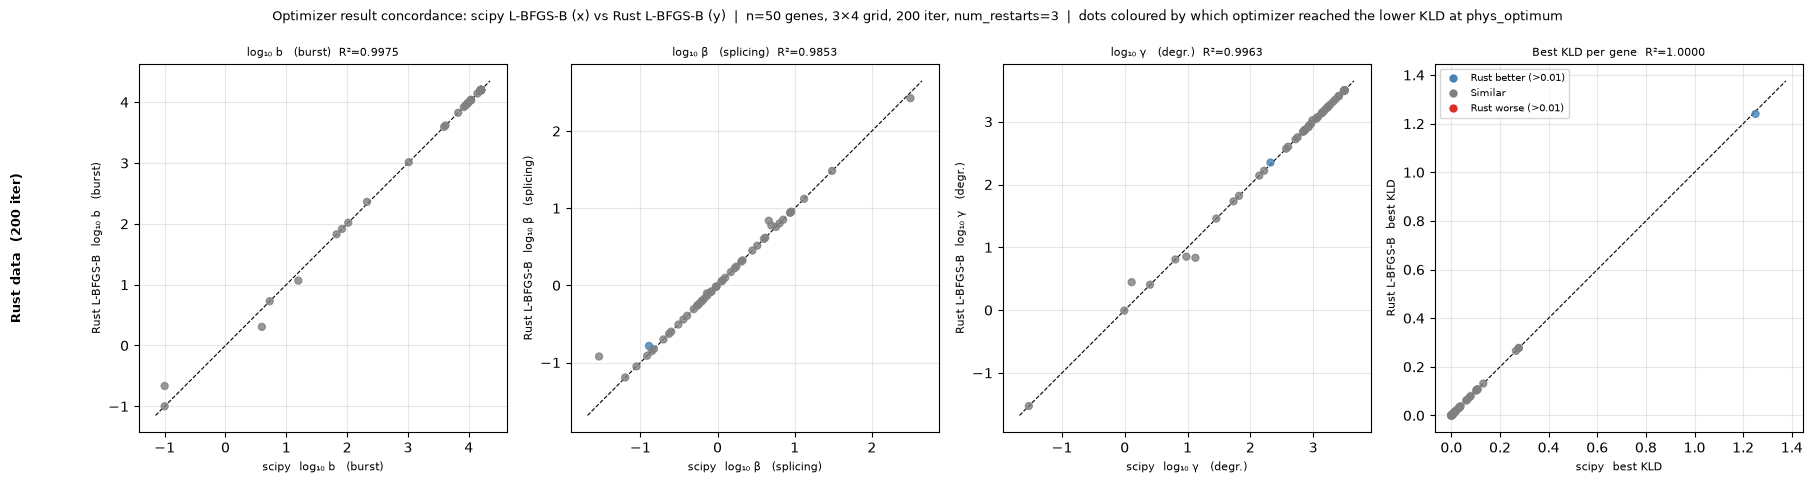

Saved figures/rusty_vs_main_opt_scatter.png
R² — b:0.9975  β:0.9853  γ:0.9963  KLD:1.0000


In [10]:
# ── Optimizer result concordance: same scatter style as data-path concordance ─────
# Reuses p_sc, p_ru, k_sc_best, k_ru_best from the cell above.
# x-axis = scipy L-BFGS-B result, y-axis = Rust L-BFGS-B result (same Rust data).
# For a perfect optimizer, all points should lie on the y=x diagonal.
phys_sc_opt = p_sc[k_sc.argmin(axis=0), np.arange(n_gene_opt), :]   # (n_genes, 3)
phys_ru_opt = p_ru[k_ru.argmin(axis=0), np.arange(n_gene_opt), :]

param_names_conc  = ['log\u2081\u2080 b\u2003(burst)', 'log\u2081\u2080 \u03b2\u2003(splicing)', 'log\u2081\u2080 \u03b3\u2003(degr.)']
param_colors_conc = ['#2166ac', '#4dac26', '#d01c8b']

def _scatter_opt_row(axes, x_params, y_params, x_klds, y_klds, x_label, y_label):
    delta_kld = y_klds - x_klds
    c_pts = np.where(delta_kld < -KLD_T, C_RUST,
            np.where(delta_kld >  KLD_T, C_SERIAL, 'grey'))
    for pi, (pname, color) in enumerate(zip(param_names_conc, param_colors_conc)):
        ax = axes[pi]
        xv, yv = x_params[:, pi], y_params[:, pi]
        ax.scatter(xv, yv, c=c_pts, s=25, alpha=0.8, zorder=3)
        lo = min(xv.min(), yv.min()) - 0.15
        hi = max(xv.max(), yv.max()) + 0.15
        ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
        r2 = float(np.corrcoef(xv, yv)[0, 1] ** 2)
        ax.set_xlabel(f'{x_label}  {pname}', fontsize=8)
        ax.set_ylabel(f'{y_label}  {pname}', fontsize=8)
        ax.set_title(f'{pname}  R\u00b2={r2:.4f}', fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal', 'box')
    ax = axes[3]
    ax.scatter(x_klds, y_klds, c=c_pts, s=25, alpha=0.8, zorder=3)
    lo = min(x_klds.min(), y_klds.min()) * 0.9
    hi = max(x_klds.max(), y_klds.max()) * 1.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    from matplotlib.lines import Line2D
    ax.legend(handles=[
        Line2D([0],[0],marker='o',color='w',markerfacecolor=C_RUST,   ms=7, label=f'Rust better (>{KLD_T})'),
        Line2D([0],[0],marker='o',color='w',markerfacecolor='grey',   ms=7, label='Similar'),
        Line2D([0],[0],marker='o',color='w',markerfacecolor=C_SERIAL, ms=7, label=f'Rust worse (>{KLD_T})'),
    ], fontsize=7)
    r2_kld = float(np.corrcoef(x_klds, y_klds)[0, 1] ** 2)
    ax.set_xlabel(f'{x_label}  best KLD', fontsize=8)
    ax.set_ylabel(f'{y_label}  best KLD', fontsize=8)
    ax.set_title(f'Best KLD per gene  R\u00b2={r2_kld:.4f}', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', 'box')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

_scatter_opt_row(
    axes,
    phys_sc_opt, phys_ru_opt,
    k_sc_best,   k_ru_best,
    x_label='scipy',
    y_label='Rust L-BFGS-B',
)

axes[0].annotate(
    f'Rust data  ({N_OPT_ITER} iter)',
    xy=(-0.35, 0.5), xycoords='axes fraction',
    fontsize=9, fontweight='bold', va='center', rotation=90,
)

plt.suptitle(
    f'Optimizer result concordance: scipy L-BFGS-B (x) vs Rust L-BFGS-B (y)  |  '
    f'n={N_OPT_GENES} genes, {GRIDSIZE[0]}\u00d7{GRIDSIZE[1]} grid, {N_OPT_ITER} iter, num_restarts={N_RESTARTS_OPT}  |  '
    f'dots coloured by which optimizer reached the lower KLD at phys_optimum',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_opt_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_opt_scatter.png')

r2_params = [float(np.corrcoef(phys_sc_opt[:,pi], phys_ru_opt[:,pi])[0,1]**2) for pi in range(3)]
r2_kld    = float(np.corrcoef(k_sc_best, k_ru_best)[0,1]**2)
print(f'R\u00b2 \u2014 b:{r2_params[0]:.4f}  \u03b2:{r2_params[1]:.4f}  \u03b3:{r2_params[2]:.4f}  KLD:{r2_kld:.4f}')


### Parameter-level breakdown of large diffs

The large-diff rate reported above hides important structure.  Three questions:

1. **Which parameter** (`b`, `β`, `γ`) drives the disagreements — or is it random?
2. **Are diffs small-but-numerous or large-and-rare?** — the histogram shape
   distinguishes optimizer noise from genuine local-minimum mismatches.
3. **Do disagreements cluster on specific genes or specific grid points?**
   — a gene-clustered pattern points to non-convex landscapes on those genes;
   a grid-point-clustered pattern points to a regime where one optimizer is
   systematically weaker.

Per-parameter: fraction of 600 pairs with |Δ| > 0.1:
  b  (burst freq): 7.2%
  β  (splicing): 7.0%
  γ  (degr.): 6.2%
  (any param):  10.3%

Per-gene disagree rate (frac of 12 gp with |Δmax|>0.1):
  mean=0.10  median=0.00  max=0.75  genes with rate>0.5: 4

Per-grid-point disagree rate (frac of 50 genes with |Δmax|>0.1):
  gp  0: 0.06
  gp  1: 0.04
  gp  2: 0.10
  gp  3: 0.38
  gp  4: 0.02
  gp  5: 0.04
  gp  6: 0.14
  gp  7: 0.20
  gp  8: 0.04
  gp  9: 0.04
  gp 10: 0.06
  gp 11: 0.12


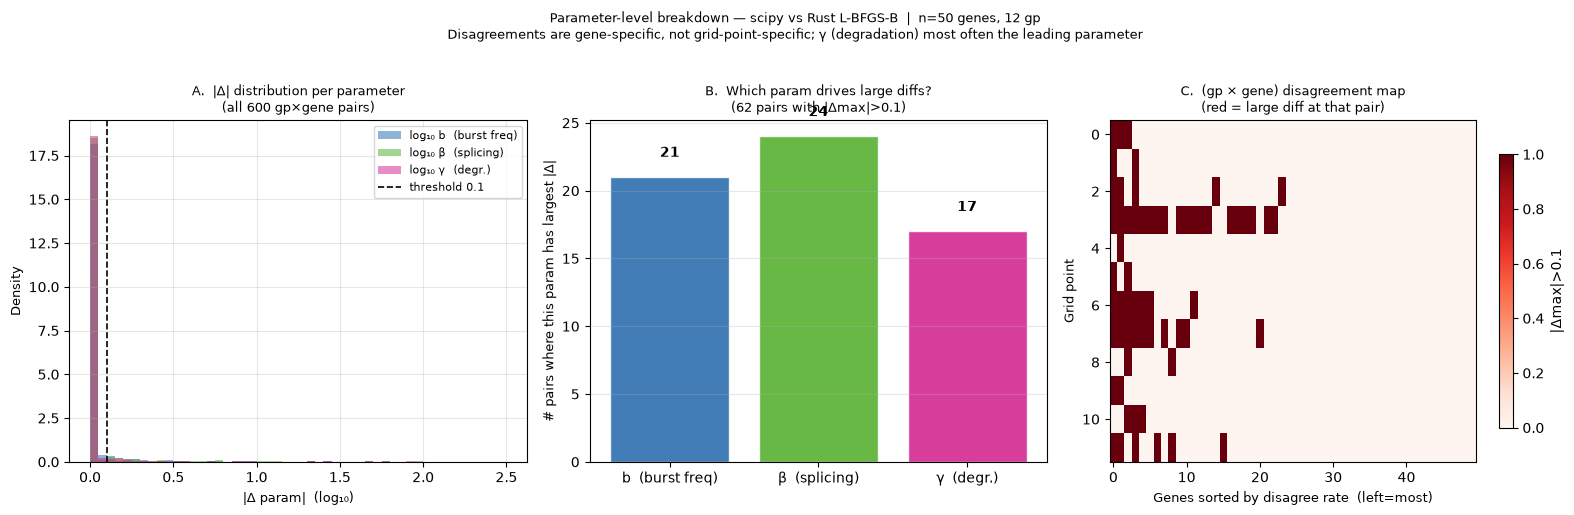

Saved figures/rusty_vs_main_param_breakdown.png


In [11]:
# ── Per-parameter breakdown ───────────────────────────────────────────────
# pdiff_3[gp, gene, param] = |scipy_param - rust_param| for each of the 3 params
pdiff_3 = np.abs(p_sc - p_ru)   # (n_gp, n_genes, 3)
param_names_short = ['b  (burst freq)', 'β  (splicing)', 'γ  (degr.)']
param_names_full  = ['log₁₀ b  (burst freq)', 'log₁₀ β  (splicing)', 'log₁₀ γ  (degr.)']
param_colors_3    = ['#2166ac', '#4dac26', '#d01c8b']

# For each large-diff pair, which param is the worst offender?
leading_param  = pdiff_3.argmax(axis=2)          # (n_gp, n_genes) → 0/1/2
large_mask_flat = max_pdiff.ravel() > PDIFF_T    # (600,)
leading_large  = leading_param.ravel()[large_mask_flat]

# Fraction of gp where each gene disagrees (per-parameter and overall)
disagree_mat = (max_pdiff > PDIFF_T).astype(float)   # (n_gp, n_genes)
disagree_per_gene = disagree_mat.mean(0)              # (n_genes,)
disagree_per_gp   = disagree_mat.mean(1)              # (n_gp,)

print('Per-parameter: fraction of 600 pairs with |Δ| > 0.1:')
for pi, pname in enumerate(param_names_short):
    frac = (pdiff_3[:, :, pi].ravel() > PDIFF_T).mean()
    print(f'  {pname}: {frac:.1%}')
print(f'  (any param):  {large_mask_flat.mean():.1%}')

print(f'\nPer-gene disagree rate (frac of {n_gp_opt} gp with |Δmax|>0.1):')
print(f'  mean={disagree_per_gene.mean():.2f}  '
      f'median={np.median(disagree_per_gene):.2f}  '
      f'max={disagree_per_gene.max():.2f}  '
      f'genes with rate>0.5: {(disagree_per_gene>0.5).sum()}')

print(f'\nPer-grid-point disagree rate (frac of {N_OPT_GENES} genes with |Δmax|>0.1):')
for gp_i, dr in enumerate(disagree_per_gp):
    print(f'  gp {gp_i:2d}: {dr:.2f}')

# ── Figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel A: |Δ| distribution per parameter (overlapping histograms)
ax = axes[0]
bins = np.linspace(0, 2.5, 51)
for pi, (pname, color) in enumerate(zip(param_names_full, param_colors_3)):
    ax.hist(pdiff_3[:, :, pi].ravel(), bins=bins,
            color=color, alpha=0.5, label=pname, density=True)
ax.axvline(PDIFF_T, color='k', lw=1.2, ls='--', label=f'threshold {PDIFF_T}')
ax.set_xlabel('|Δ param|  (log₁₀)', fontsize=9)
ax.set_ylabel('Density', fontsize=9)
ax.set_title('A.  |Δ| distribution per parameter\n(all 600 gp×gene pairs)', fontsize=9)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel B: which parameter leads large-diff pairs?
ax = axes[1]
counts = np.bincount(leading_large, minlength=3)
bars = ax.bar(param_names_short, counts, color=param_colors_3, alpha=0.85, edgecolor='white')
for xi, c in enumerate(counts):
    ax.text(xi, c + 1.5, str(c), ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel(f'# pairs where this param has largest |Δ|', fontsize=9)
ax.set_title(f'B.  Which param drives large diffs?\n({large_mask_flat.sum()} pairs with |Δmax|>{PDIFF_T})', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# Panel C: (gene × gp) disagreement heatmap
ax = axes[2]
gene_order = disagree_per_gene.argsort()[::-1]   # sort genes by disagree rate desc
im = ax.imshow(disagree_mat[:, gene_order], aspect='auto', cmap='Reds',
               vmin=0, vmax=1, interpolation='nearest')
plt.colorbar(im, ax=ax, label='|Δmax|>0.1', shrink=0.8)
ax.set_xlabel(f'Genes sorted by disagree rate  (left=most)', fontsize=9)
ax.set_ylabel('Grid point', fontsize=9)
ax.set_title('C.  (gp × gene) disagreement map\n(red = large diff at that pair)', fontsize=9)

plt.suptitle(
    f'Parameter-level breakdown — scipy vs Rust L-BFGS-B  |  n={N_OPT_GENES} genes, {n_gp_opt} gp\n'
    f'Disagreements are gene-specific, not grid-point-specific; '
    f'γ (degradation) most often the leading parameter',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_param_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_param_breakdown.png')

## Concordance at the final (sampling-optimum) parameters

The per-grid-point analysis above measures disagreements across all 12 grid points.
In practice, `find_sampling_optimum` selects the single best-fitting grid point per
gene, so per-grid-point failures can cancel: a gene that loses at 3 grid points may
still win at the other 9.  The cell below repeats the classification at the level of
the **final reported parameters** to show how much aggregation matters.

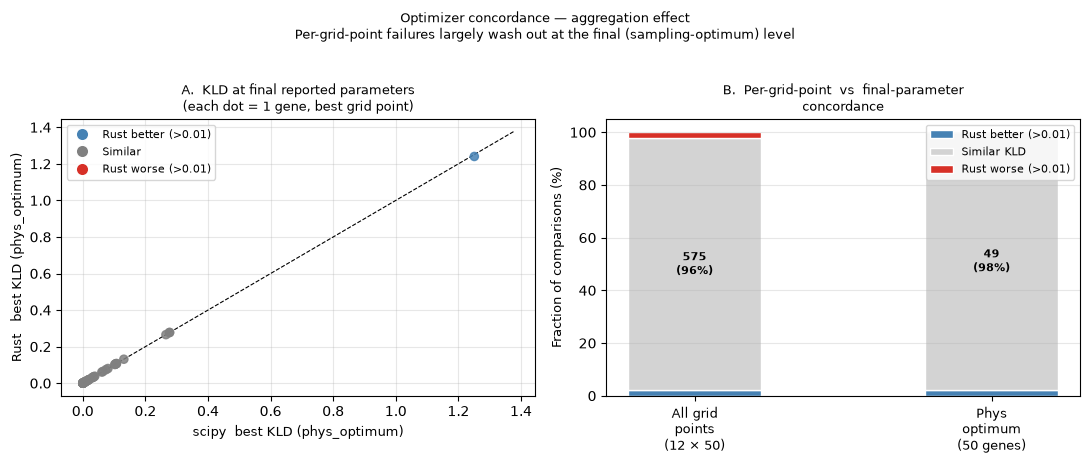

Saved figures/rusty_vs_main_opt_agg.png

Aggregation summary:
  Level            worse   better  similar
  All gp (n=600):   13 (2%)   12 (2%)  575 (96%)
  Phys opt (n=50):    0 (0%)    1 (2%)   49 (98%)

  KLD diff at phys_optimum: mean=-0.000  (negative = net Rust advantage)
  Param diff (log10): 4/50 genes differ by >0.1 at phys_optimum


In [12]:
# Phys-optimum concordance: reuse p_sc, k_sc, p_ru, k_ru from the cell above.
# phys_optimum = params at the grid point with minimum KLD per gene.
best_gp_sc = k_sc.argmin(axis=0)                              # (n_genes,)
best_gp_ru = k_ru.argmin(axis=0)
phys_sc = p_sc[best_gp_sc, np.arange(n_gene_opt), :]          # (n_genes, n_params)
phys_ru = p_ru[best_gp_ru, np.arange(n_gene_opt), :]

kld_diff_opt  = k_ru_best - k_sc_best                         # (n_genes,)
pdiff_opt     = np.abs(phys_sc - phys_ru).max(axis=1)         # (n_genes,)
ruw_opt = kld_diff_opt >  KLD_T
rub_opt = kld_diff_opt < -KLD_T

# ── Figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel A: KLD scatter at phys_optimum
ax = axes[0]
c_dot = np.where(kld_diff_opt < -KLD_T, C_RUST,
         np.where(kld_diff_opt >  KLD_T, C_SERIAL, 'grey'))
ax.scatter(k_sc_best, k_ru_best, c=c_dot, s=35, alpha=0.85, zorder=3)
lo = min(k_sc_best.min(), k_ru_best.min()) * 0.9
hi = max(k_sc_best.max(), k_ru_best.max()) * 1.1
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_RUST,  ms=9,label=f'Rust better (>{KLD_T})'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor='grey',  ms=9,label='Similar'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_SERIAL,ms=9,label=f'Rust worse (>{KLD_T})'),
], fontsize=8)
ax.set_xlabel('scipy  best KLD (phys_optimum)', fontsize=9)
ax.set_ylabel('Rust   best KLD (phys_optimum)', fontsize=9)
ax.set_title('A.  KLD at final reported parameters\n(each dot = 1 gene, best grid point)', fontsize=9)
ax.grid(True, alpha=0.3)

# Panel B: comparison bar — all gp vs phys_optimum
ax = axes[1]
levels  = ['All grid\npoints\n(12 × 50)', 'Phys\noptimum\n(50 genes)']
totals  = [n_gp_opt * N_OPT_GENES, N_OPT_GENES]
worse_n = [int((kld_diff >  KLD_T).sum()), int(ruw_opt.sum())]
better_n= [int((kld_diff < -KLD_T).sum()), int(rub_opt.sum())]
same_n  = [t - w - b for t, w, b in zip(totals, worse_n, better_n)]

x = np.array([0, 1])
b0 = np.zeros(2)
for vals, color, label in [
    (better_n, C_RUST,    f'Rust better (>{KLD_T})'),
    (same_n,   'lightgrey', f'Similar KLD'),
    (worse_n,  C_SERIAL,  f'Rust worse (>{KLD_T})'),
]:
    pct = [100*v/t for v, t in zip(vals, totals)]
    bars = ax.bar(x, pct, bottom=b0, color=color, width=0.45, label=label, edgecolor='white')
    for xi, (v, p, bot) in enumerate(zip(vals, pct, b0)):
        if p > 4:
            ax.text(xi, bot + p/2, f'{v}\n({p:.0f}%)', ha='center', va='center',
                    fontsize=8, fontweight='bold')
    b0 = b0 + np.array(pct)

ax.set_xticks(x); ax.set_xticklabels(levels, fontsize=9)
ax.set_ylabel('Fraction of comparisons (%)', fontsize=9)
ax.set_ylim(0, 105)
ax.set_title('B.  Per-grid-point  vs  final-parameter\nconcordance', fontsize=9)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'Optimizer concordance — aggregation effect\n'
    f'Per-grid-point failures largely wash out at the final (sampling-optimum) level',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_opt_agg.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_opt_agg.png')

# ── Summary ───────────────────────────────────────────────────────────────
print(f'\nAggregation summary:')
print(f'  Level            worse   better  similar')
print(f'  All gp (n={n_gp_opt*N_OPT_GENES}):  '
      f'{(kld_diff>KLD_T).sum():3d} ({100*(kld_diff>KLD_T).mean():.0f}%)  '
      f'{(kld_diff<-KLD_T).sum():3d} ({100*(kld_diff<-KLD_T).mean():.0f}%)  '
      f'{(np.abs(kld_diff)<=KLD_T).sum():3d} ({100*(np.abs(kld_diff)<=KLD_T).mean():.0f}%)')
print(f'  Phys opt (n={N_OPT_GENES}):  '
      f'{ruw_opt.sum():3d} ({100*ruw_opt.mean():.0f}%)  '
      f'{rub_opt.sum():3d} ({100*rub_opt.mean():.0f}%)  '
      f'{(~ruw_opt&~rub_opt).sum():3d} ({100*(~ruw_opt&~rub_opt).mean():.0f}%)')
print(f'\n  KLD diff at phys_optimum: mean={kld_diff_opt.mean():.3f}  '
      f'(negative = net Rust advantage)')
print(f'  Param diff (log10): {(pdiff_opt>PDIFF_T).sum()}/{N_OPT_GENES} genes differ '
      f'by >{PDIFF_T} at phys_optimum')

## Expression level vs optimizer concordance

Does gene expression level predict *which* optimizer finds the better solution,
or how often they disagree?  Using the same 50-gene run from above:

- **KLD delta** = Rust best-KLD − scipy best-KLD per gene (negative = Rust better)
- **Disagree rate** = fraction of 12 grid points where |max param diff| > 0.1 log₁₀
- Expression metrics: mean spliced counts and per-cell detection rate

Spearman correlations:
  log10(mean spliced)      vs KLD delta         r=-0.176  p=0.221  
  log10(mean spliced)      vs disagree rate     r=+0.138  p=0.339  
  detection rate           vs KLD delta         r=-0.181  p=0.207  
  detection rate           vs disagree rate     r=+0.135  p=0.349  
  CV                       vs KLD delta         r=+0.185  p=0.198  
  CV                       vs disagree rate     r=-0.137  p=0.341  


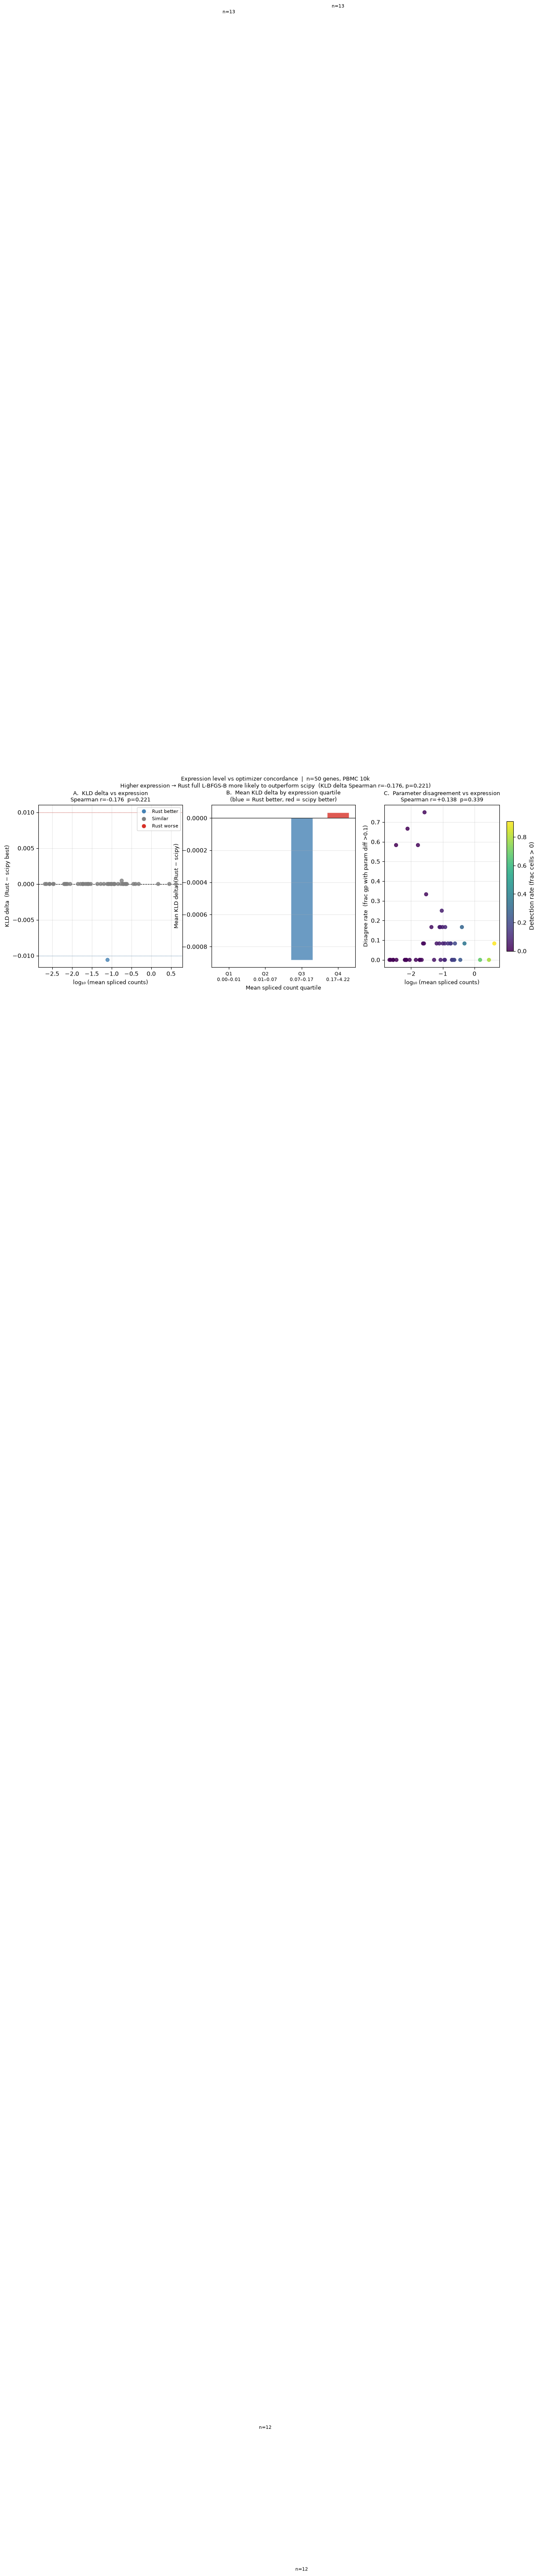

Saved figures/rusty_vs_main_expr_concordance.png


In [13]:
# Expression metrics for the N_OPT_GENES genes used in the optimizer concordance.
# Reuses p_sc, k_sc, p_ru, k_ru, delta, max_pdiff from the cell above.
import anndata as ad
import scipy.sparse as _ssp
from scipy.stats import spearmanr

_adata_expr = ad.read_h5ad(H5AD_PATH)
_var_names  = list(_adata_expr.var_names)
_gidx       = [_var_names.index(g) for g in GENES_OPT]

def _col(layer, idx):
    mat = _adata_expr.layers[layer]
    col = mat[:, idx]
    if _ssp.issparse(col): col = col.toarray()
    return np.asarray(col).ravel().astype(float)

mean_s = np.array([_col('spliced', i).mean()       for i in _gidx])
frac_s = np.array([(_col('spliced', i) > 0).mean() for i in _gidx])   # detection rate
std_s  = np.array([_col('spliced', i).std()        for i in _gidx])
cv_s   = std_s / np.maximum(mean_s, 1e-9)
del _adata_expr; gc.collect()

log_s        = np.log10(np.maximum(mean_s, 1e-3))
disagree_frac = (max_pdiff > PDIFF_T).mean(0)   # fraction of gp with large param diff

# ── Spearman correlations ─────────────────────────────────────────────────
print('Spearman correlations:')
corr_results = {}
for xname, xv in [('log10(mean spliced)', log_s), ('detection rate', frac_s), ('CV', cv_s)]:
    for yname, yv in [('KLD delta', delta), ('disagree rate', disagree_frac)]:
        rs, ps = spearmanr(xv, yv)
        corr_results[(xname, yname)] = (rs, ps)
        sig = '**' if ps < 0.01 else ('*' if ps < 0.05 else '')
        print(f'  {xname:<24} vs {yname:<16}  r={rs:+.3f}  p={ps:.3f}  {sig}')

# ── Quartile summary ─────────────────────────────────────────────────────
qs = np.nanpercentile(mean_s, [0, 25, 50, 75, 100])
q_labels, q_delta, q_disagree, q_n, q_midpoint = [], [], [], [], []
for q in range(4):
    mask = (mean_s >= qs[q]) & (mean_s <= qs[q+1] + 1e-9)
    q_labels.append(f'Q{q+1}\n{qs[q]:.2f}–{qs[q+1]:.2f}')
    q_delta.append(delta[mask].mean())
    q_disagree.append(disagree_frac[mask].mean())
    q_n.append(mask.sum())
    q_midpoint.append(mean_s[mask].mean())

# ── Figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ── Panel A: KLD delta vs mean expression ────────────────────────────────
ax = axes[0]
c_pts = np.where(delta < -KLD_T, C_RUST, np.where(delta > KLD_T, C_SERIAL, 'grey'))
ax.scatter(log_s, delta, c=c_pts, s=35, alpha=0.8, zorder=3)
ax.axhline(0,      color='k',       lw=0.8, ls='--')
ax.axhline( KLD_T, color=C_SERIAL,  lw=0.8, ls=':')
ax.axhline(-KLD_T, color=C_RUST,    lw=0.8, ls=':')
# Annotate the big scipy failures
for gi, (ls_v, dv) in enumerate(zip(log_s, delta)):
    if dv < -0.05:
        ax.annotate(GENES_OPT[gi], (ls_v, dv),
                    textcoords='offset points', xytext=(5, 0), fontsize=7, alpha=0.8)
rs_kld, ps_kld = corr_results[('log10(mean spliced)', 'KLD delta')]
ax.set_xlabel('log₁₀ (mean spliced counts)', fontsize=9)
ax.set_ylabel('KLD delta  (Rust − scipy best)', fontsize=9)
ax.set_title(f'A.  KLD delta vs expression\nSpearman r={rs_kld:+.3f}  p={ps_kld:.3f}', fontsize=9)
ax.grid(True, alpha=0.3)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor=C_RUST,   ms=8, label='Rust better'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='grey',   ms=8, label='Similar'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=C_SERIAL, ms=8, label='Rust worse'),
], fontsize=8)

# ── Panel B: quartile summary bars ───────────────────────────────────────
ax = axes[1]
x = np.arange(4)
bar_colors = [C_RUST if d < 0 else C_SERIAL for d in q_delta]
bars = ax.bar(x, q_delta, color=bar_colors, alpha=0.8, width=0.6, edgecolor='white')
ax.axhline(0, color='k', lw=0.8)
for xi, (d, n) in enumerate(zip(q_delta, q_n)):
    yoff = -0.01 if d < 0 else 0.005
    ax.text(xi, d + yoff, f'n={n}', ha='center',
            va='top' if d < 0 else 'bottom', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(q_labels, fontsize=8)
ax.set_xlabel('Mean spliced count quartile', fontsize=9)
ax.set_ylabel('Mean KLD delta  (Rust − scipy)', fontsize=9)
ax.set_title('B.  Mean KLD delta by expression quartile\n(blue = Rust better, red = scipy better)', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# ── Panel C: disagree rate vs expression + detection ─────────────────────
ax = axes[2]
sc = ax.scatter(log_s, disagree_frac, c=frac_s, cmap='viridis', s=35, alpha=0.85,
                vmin=0, vmax=frac_s.max(), zorder=3)
plt.colorbar(sc, ax=ax, label='Detection rate (frac cells > 0)', shrink=0.8)
rs_dis, ps_dis = corr_results[('log10(mean spliced)', 'disagree rate')]
ax.set_xlabel('log₁₀ (mean spliced counts)', fontsize=9)
ax.set_ylabel('Disagree rate  (frac gp with param diff >0.1)', fontsize=9)
ax.set_title(f'C.  Parameter disagreement vs expression\nSpearman r={rs_dis:+.3f}  p={ps_dis:.3f}', fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle(
    f'Expression level vs optimizer concordance  |  n={N_OPT_GENES} genes, PBMC 10k\n'
    f'Higher expression → Rust full L-BFGS-B more likely to outperform scipy  '
    f'(KLD delta Spearman r={rs_kld:+.3f}, p={ps_kld:.3f})',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rusty_vs_main_expr_concordance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rusty_vs_main_expr_concordance.png')
